# Q2 – Notebook 1 of 3: Data Loading and Preprocessing
**NLP Group Assignment 2 · Question 2: 5-class Amazon review rating prediction**

This notebook loads the Amazon star-rating dataset and builds the **two distinct preprocessing pipelines** required by the assignment:
1. **Classic pipeline** (BiGRU baseline): cleaning, spaCy tokenisation, vocabulary with a minimum-frequency threshold, fixed length 200, fastText embedding matrix.
2. **RoBERTa pipeline**: `RobertaTokenizerFast` (byte-level BPE), special tokens `<s>`/`</s>`, truncation to 256, attention mask and dynamic padding with a data collator.

The results are saved to Google Drive (`GROUP_ASSIGNMENT_2/Q2_final/prep`) and are loaded by notebook 2 (BiGRU baseline) and notebook 3 (RoBERTa).

**Order of the notebooks:** 1 (this one) → 2 (baseline) → 3 (RoBERTa, ablation, comparison). Runtime: about 10 minutes (about 25 minutes if the fastText vectors have to be downloaded).

In [1]:
!pip -q install -U datasets spacy scikit-learn seaborn > /dev/null 2>&1

import os
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
import re, time, json, collections, zipfile, urllib.request, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import transformers, datasets
from transformers import AutoTokenizer, RobertaTokenizerFast, DataCollatorWithPadding
transformers.logging.set_verbosity_error(); datasets.logging.set_verbosity_error()

try:
    from google.colab import drive
    drive.mount('/content/drive')
    CKPT_DIR = '/content/drive/MyDrive/GROUP_ASSIGNMENT_2/Q2_final'
except ImportError:
    CKPT_DIR = './Q2_final'
PREP_DIR = f'{CKPT_DIR}/prep'            # artifacts written by notebook 1
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(PREP_DIR, exist_ok=True)

print('artifacts will be saved in:', PREP_DIR)

Mounted at /content/drive
artifacts will be saved in: /content/drive/MyDrive/GROUP_ASSIGNMENT_2/Q2_final/prep


## 0. Configuration

In [2]:
MAX_LEN_RNN, MIN_FREQ, EMB_DIM = 200, 3, 300      # classic pipeline
MODEL_NAME, MAX_LEN_RB = 'roberta-base', 256       # RoBERTa pipeline
PAD, UNK = 0, 1

## 1. Data loading
`SetFit/amazon_reviews_multi_en`: 200,000 train / 5,000 validation / 5,000 test reviews; labels 0–4 correspond to 1–5 stars. The printed schema shows whether the review title and body are already merged into one `text` field; `build_df` concatenates `review_title` and `review_body` if those columns exist.

In [3]:
from datasets import load_dataset
ds = load_dataset('SetFit/amazon_reviews_multi_en')
print(ds['train'].features)

def build_df(split):
    df = ds[split].to_pandas()
    if 'review_title' in df.columns and 'review_body' in df.columns:
        df['text'] = df['review_title'].fillna('').str.strip() + '. ' + df['review_body'].fillna('').str.strip()
    df['text'] = df['text'].fillna('').astype(str)
    return df[['text', 'label']]

train_df, val_df, test_df = build_df('train'), build_df('validation'), build_df('test')
assert set(train_df.label.unique()) == {0, 1, 2, 3, 4}
assert (train_df.text.str.len() > 0).all() and (val_df.text.str.len() > 0).all() and (test_df.text.str.len() > 0).all()
print(len(train_df), len(val_df), len(test_df))
for name, d in (('train', train_df), ('validation', val_df), ('test', test_df)):
    print(f'{name:10s} class counts (1-5 stars):', d.label.value_counts().sort_index().tolist())
print('\nraw examples:')
for i in range(3): print(f'  [{train_df.label[i]+1}★]', train_df.text[i][:150])

README.md:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

train.jsonl: reconstructing file:   0%|          |  0.00B / 47.4MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/1.18M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

{'id': Value('string'), 'text': Value('string'), 'label': Value('int64'), 'label_text': Value('string')}
200000 5000 5000
train      class counts (1-5 stars): [40000, 40000, 40000, 40000, 40000]
validation class counts (1-5 stars): [1000, 1000, 1000, 1000, 1000]
test       class counts (1-5 stars): [1000, 1000, 1000, 1000, 1000]

raw examples:
  [1★] Arrived broken. Manufacturer defect. Two of the legs of the base were not completely formed, so there was no way to insert the casters. I unpackaged t
  [1★] the cabinet dot were all detached from backing... got me
  [1★] I received my first order of this product and it was broke so I ordered it again. The second one was broke in more places than the first. I can't blam


## 2. Classic preprocessing (BiGRU baseline)
Lowercase → remove HTML tags and URLs → spaCy tokenizer → vocabulary from the **training split only** (minimum frequency 3; `<pad>`=0, `<unk>`=1) → truncate/pad to 200 tokens.

In [4]:
import spacy
nlp = spacy.blank('en')
URL_RE, HTML_RE, WS_RE = re.compile(r'(https?://\S+|www\.\S+)'), re.compile(r'<[^>]+>'), re.compile(r'\s+')

def clean_text(t):
    t = HTML_RE.sub(' ', t.lower()); t = URL_RE.sub(' ', t)
    return WS_RE.sub(' ', t).strip()

def tokenize_all(texts):
    cleaned = [clean_text(t) for t in texts]
    return [[tok.text for tok in d if not tok.is_space] for d in nlp.pipe(cleaned, batch_size=2000)]

# demonstration of the pipeline on one review containing HTML and a URL
demo = 'Great <b>value</b>!! Details at http://example.com/x  — I LOVE it, 5 stars.'
print('raw    :', demo); print('cleaned:', clean_text(demo)); print('tokens :', tokenize_all([demo])[0])

t0 = time.time()
tr_tok, va_tok, te_tok = (tokenize_all(d.text.tolist()) for d in (train_df, val_df, test_df))
print('\ntokenized train/val/test in %.0fs' % (time.time() - t0))

raw    : Great <b>value</b>!! Details at http://example.com/x  — I LOVE it, 5 stars.
cleaned: great value !! details at — i love it, 5 stars.
tokens : ['great', 'value', '!', '!', 'details', 'at', '—', 'i', 'love', 'it', ',', '5', 'stars', '.']

tokenized train/val/test in 39s


In [5]:
cnt = collections.Counter(w for s in tr_tok for w in s)                  # TRAIN ONLY
itos = ['<pad>', '<unk>'] + [w for w, c in cnt.most_common() if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}

def encode(tok_lists, max_len=MAX_LEN_RNN):
    X = np.zeros((len(tok_lists), max_len), dtype=np.int64)               # 0 = <pad>
    for i, s in enumerate(tok_lists):
        ids = [stoi.get(w, UNK) for w in s[:max_len]] or [UNK]            # unknown words -> <unk>
        X[i, :len(ids)] = ids
    return X

Xtr, Xva, Xte = encode(tr_tok), encode(va_tok), encode(te_tok)
ytr, yva, yte = train_df.label.values, val_df.label.values, test_df.label.values
te_len = np.array([len(s) for s in te_tok])
tr_len = np.array([len(s) for s in tr_tok])
trunc_rnn = float(np.mean(tr_len > MAX_LEN_RNN) * 100)
unk_rate = float((Xtr == UNK).sum() / (Xtr != PAD).sum() * 100)
print(f'vocabulary size (incl. <pad>, <unk>): {len(itos):,}  (words with frequency >= {MIN_FREQ} among {len(cnt):,} distinct training words)')
print(f'train reviews truncated at {MAX_LEN_RNN} tokens: {trunc_rnn:.2f}% | <unk> share of training tokens: {unk_rate:.2f}% | max length {tr_len.max()}')
print('\nexample test review:')
print('  tokens:', te_tok[0][:12]); print('  ids   :', Xte[0][:12].tolist())
del tr_tok, va_tok

vocabulary size (incl. <pad>, <unk>): 24,570  (words with frequency >= 3 among 48,373 distinct training words)
train reviews truncated at 200 tokens: 0.79% | <unk> share of training tokens: 0.39% | max length 910

example test review:
  tokens: ['these', 'are', 'awful', '.', 'they', 'are', 'see', 'through', ',', 'the', 'fabric', 'feels']
  ids   : [38, 30, 890, 2, 24, 30, 151, 204, 8, 3, 449, 410]


### fastText embedding matrix
Each vocabulary word gets its 300-d fastText `crawl-300d-2M` vector; words that are not in fastText get small random vectors and `<pad>` is zero. The matrix is cached on Drive; the 1.5 GB download is only needed the first time.

In [6]:
EMB_FILE, EMB_META = f'{CKPT_DIR}/emb_matrix.npy', f'{CKPT_DIR}/emb_meta.json'
if os.path.exists(EMB_FILE) and os.path.exists(EMB_META) and np.load(EMB_FILE, mmap_mode='r').shape[0] == len(itos):
    emb_matrix, FT = np.load(EMB_FILE), json.load(open(EMB_META)); print('embedding matrix loaded from cache')
else:
    zpath = '/content/crawl-300d-2M.vec.zip' if os.path.isdir('/content') else './crawl-300d-2M.vec.zip'
    if not os.path.exists(zpath):
        print('downloading fastText vectors (~1.5 GB)...')
        urllib.request.urlretrieve('https://dl.fbaipublicfiles.com/fasttext/vectors-english/crawl-300d-2M.vec.zip', zpath)
    rng = np.random.RandomState(0)
    emb_matrix = rng.normal(0, 0.1, (len(itos), EMB_DIM)).astype('float32'); emb_matrix[PAD] = 0
    found = 0
    with zipfile.ZipFile(zpath) as z, z.open('crawl-300d-2M.vec') as f:
        next(f)
        for line in f:
            parts = line.rstrip().split(b' ')
            i = stoi.get(parts[0].decode('utf8', 'ignore'))
            if i is not None and i > UNK and len(parts) == EMB_DIM + 1:
                emb_matrix[i] = np.asarray(parts[1:], dtype='float32'); found += 1
    FT = dict(found=found, total=len(itos) - 2)
    np.save(EMB_FILE, emb_matrix); json.dump(FT, open(EMB_META, 'w'))
print(f'fastText coverage: {FT["found"]:,}/{FT["total"]:,} = {100*FT["found"]/FT["total"]:.1f}% | embedding matrix {emb_matrix.shape}')

embedding matrix loaded from cache
fastText coverage: 24,131/24,568 = 98.2% | embedding matrix (24570, 300)


## 3. RoBERTa preprocessing
`RobertaTokenizerFast` (byte-level BPE) adds `<s>` and `</s>`, truncates to 256 tokens and returns the `attention_mask`. The text is **not** lowercased or cleaned (RoBERTa was pre-trained on raw cased text), and sequences are not padded in advance: `DataCollatorWithPadding` pads every batch only to its longest sequence (**dynamic padding**), which speeds up training.

In [7]:
tok_rb = RobertaTokenizerFast.from_pretrained(MODEL_NAME)
print('tokenizer class:', type(tok_rb).__name__)

def rb_encode(texts):
    ids = []
    for i in range(0, len(texts), 20000):
        ids.extend(tok_rb(texts[i:i + 20000], truncation=True, max_length=MAX_LEN_RB)['input_ids'])
    return ids

t0 = time.time()
rb_tr, rb_va, rb_te = (rb_encode(d.text.tolist()) for d in (train_df, val_df, test_df))
print('encoded train/val/test in %.0fs' % (time.time() - t0))
rb_len = np.array([len(x) for x in rb_tr])
trunc_rb = float(np.mean(rb_len >= MAX_LEN_RB) * 100)
print(f'train reviews truncated at {MAX_LEN_RB} tokens: {trunc_rb:.2f}% | mean length {rb_len.mean():.1f} | max length {rb_len.max()}')
print('\nexample (byte-level BPE with special tokens):')
print(tok_rb.convert_ids_to_tokens(rb_te[0][:14]))

# dynamic padding: a batch is padded only to the longest sequence in the batch
collator = DataCollatorWithPadding(tok_rb)
batch = collator([{'input_ids': x, 'attention_mask': [1] * len(x)} for x in rb_te[:4]])
print('\nbatch of 4 reviews, lengths:', [len(x) for x in rb_te[:4]], '-> padded tensor', tuple(batch['input_ids'].shape))
print('attention_mask of the shortest review:\n', batch['attention_mask'][int(np.argmin([len(x) for x in rb_te[:4]]))].tolist())

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

tokenizer class: RobertaTokenizer
encoded train/val/test in 26s
train reviews truncated at 256 tokens: 0.39% | mean length 42.3 | max length 256

example (byte-level BPE with special tokens):
['<s>', 'These', 'Ġare', 'ĠAW', 'FUL', '.', 'ĠThey', 'Ġare', 'Ġsee', 'Ġthrough', ',', 'Ġthe', 'Ġfabric', 'Ġfeels']

batch of 4 reviews, lengths: [63, 18, 18, 118] -> padded tensor (4, 118)
attention_mask of the shortest review:
 [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


### Overview figure: class balance and review lengths

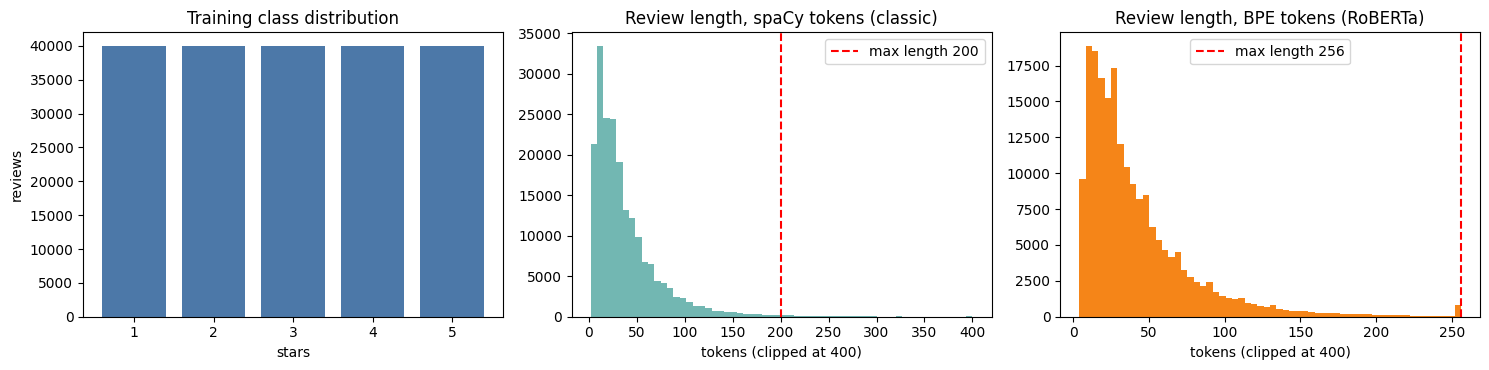

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].bar(range(1, 6), train_df.label.value_counts().sort_index().values, color='#4C78A8')
ax[0].set_title('Training class distribution'); ax[0].set_xlabel('stars'); ax[0].set_ylabel('reviews')
ax[1].hist(np.minimum(tr_len, 400), bins=60, color='#72B7B2'); ax[1].axvline(MAX_LEN_RNN, color='r', ls='--', label=f'max length {MAX_LEN_RNN}')
ax[1].set_title('Review length, spaCy tokens (classic)'); ax[1].set_xlabel('tokens (clipped at 400)'); ax[1].legend()
ax[2].hist(np.minimum(rb_len, 400), bins=60, color='#F58518'); ax[2].axvline(MAX_LEN_RB, color='r', ls='--', label=f'max length {MAX_LEN_RB}')
ax[2].set_title('Review length, BPE tokens (RoBERTa)'); ax[2].set_xlabel('tokens (clipped at 400)'); ax[2].legend()
plt.tight_layout(); plt.savefig(f'{PREP_DIR}/prep_overview.png', dpi=150); plt.show()

## 4. Summary of the preprocessing and saving of the artifacts
The artifacts below are loaded by notebooks 2 and 3, so that both models use exactly the same splits and encodings.

In [9]:
def pack(ids):                       # variable-length id lists -> flat array + lengths (compact storage)
    return np.array([len(x) for x in ids], dtype=np.int32), np.concatenate([np.asarray(x, dtype=np.int32) for x in ids])

np.savez_compressed(f'{PREP_DIR}/classic.npz', Xtr=Xtr, Xva=Xva, Xte=Xte, ytr=ytr, yva=yva, yte=yte, te_len=te_len)
json.dump(itos, open(f'{PREP_DIR}/vocab.json', 'w'))
arrs = {}
for name, ids in (('train', rb_tr), ('val', rb_va), ('test', rb_te)):
    arrs[f'{name}_lens'], arrs[f'{name}_flat'] = pack(ids)
np.savez_compressed(f'{PREP_DIR}/roberta_ids.npz', **arrs)
json.dump(test_df.text.tolist(), open(f'{PREP_DIR}/test_texts.json', 'w'))          # raw test reviews (lossless), used for the qualitative analysis

# sanity check: reload and compare
Z = np.load(f'{PREP_DIR}/roberta_ids.npz')
back = np.split(Z['test_flat'], np.cumsum(Z['test_lens'])[:-1])
assert all(a.tolist() == b for a, b in zip(back, rb_te)) and len(back) == len(rb_te)
assert (np.load(f'{PREP_DIR}/classic.npz')['Xte'] == Xte).all()
assert json.load(open(f'{PREP_DIR}/test_texts.json')) == test_df.text.tolist()

info = dict(n_train=len(train_df), n_val=len(val_df), n_test=len(test_df), vocab_size=len(itos), max_len_rnn=MAX_LEN_RNN, trunc_rnn_pct=trunc_rnn,
            max_len_rb=MAX_LEN_RB, trunc_rb_pct=trunc_rb, fasttext=FT)
json.dump(info, open(f'{PREP_DIR}/prep_info.json', 'w'), indent=1)
print(json.dumps(info, indent=1))
for f in sorted(os.listdir(PREP_DIR)): print(f'{f:22s} {os.path.getsize(os.path.join(PREP_DIR, f))/1e6:8.1f} MB')

{
 "n_train": 200000,
 "n_val": 5000,
 "n_test": 5000,
 "vocab_size": 24570,
 "max_len_rnn": 200,
 "trunc_rnn_pct": 0.7915,
 "max_len_rb": 256,
 "trunc_rb_pct": 0.394,
 "fasttext": {
  "found": 24131,
  "total": 24568
 }
}
classic.npz                17.2 MB
prep_info.json              0.0 MB
prep_overview.png           0.1 MB
roberta_ids.npz            14.3 MB
test_texts.json             0.9 MB
vocab.json                  0.3 MB


### Summary
| | Classic pipeline (BiGRU) | RoBERTa pipeline |
|---|---|---|
| Text normalisation | lowercase, HTML/URL removal | none (raw text) |
| Tokeniser | spaCy (word level) | `RobertaTokenizerFast` (byte-level BPE) |
| Vocabulary | training split only, min. frequency 3 (see printed size) | pre-trained, 50,265 BPE tokens |
| Special tokens | `<pad>`=0, `<unk>`=1 | `<s>`, `</s>`, `<pad>` |
| Length handling | truncate/pad to 200 | truncate to 256, dynamic padding per batch |
| Embeddings | fastText `crawl-300d-2M` (coverage printed above) | learned during pre-training and fine-tuned |

All numbers (vocabulary size, truncation rates, coverage) are printed by the cells above and saved in `prep/prep_info.json`. **Next:** notebook 2 (BiGRU + attention baseline).